In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

ROOT = Path.cwd()
if ROOT.name == 'figure_code':
    ROOT = ROOT.parent

DATA_DIR = ROOT / 'data'

data_dir = DATA_DIR / 'ot_validation'
plan_dir = data_dir / 'transport_plans'

mass_df = pd.read_csv(data_dir / 'scene_mass.csv')
alignment_df = pd.read_csv(data_dir / 'scene_alignment.csv')
scene_order = pd.read_csv(data_dir / 'encoding_scene_order.csv').sort_values('encoding_order')
examples = pd.read_csv(data_dir / 'example_subjects.csv')

enc_order = scene_order['scene'].astype(int).tolist()
enc_index = {sid: i for i, sid in enumerate(enc_order)}
n_scene = len(enc_order)

### fig 1 example subject plot

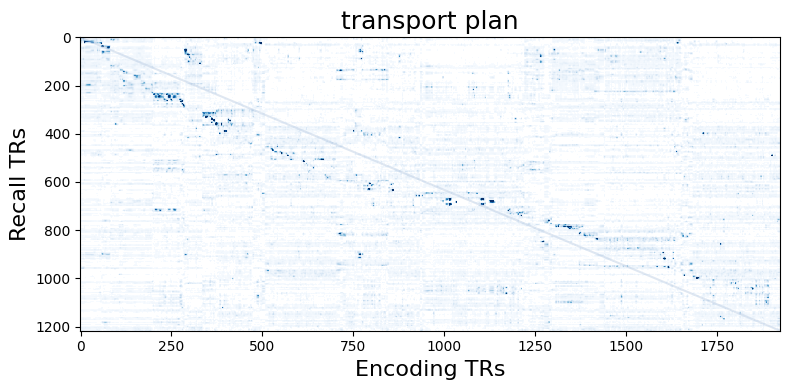

In [2]:
sub = 13
fgw = np.load(plan_dir / f'sub-{sub:02d}_FGW.npy')

vmin, vmax = np.nanpercentile(fgw, [50, 99.9])

cmap = plt.cm.Blues.copy()
cmap.set_under('white')
cmap.set_bad('white')

fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')
ax.set_facecolor('white')

ax.imshow(fgw, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)

h, w = fgw.shape
ax.plot([0, w - 1], [0, h - 1], color='#B0C4DE', alpha=0.4)

ax.set_xlabel('Encoding TRs', fontsize=16)
ax.set_ylabel('Recall TRs', fontsize=16)
ax.set_title('transport plan', fontsize=18)

fig.tight_layout()

### fig 2.

In [14]:
recall_rate = mass_df.groupby('scene')['recalled'].mean()
partial_scenes = recall_rate[(recall_rate > 0) & (recall_rate < 1)].index

within_scene = (
    mass_df.loc[mass_df['scene'].isin(partial_scenes)]
    .groupby(['scene', 'recalled'])['mass_per_tr']
    .mean()
    .unstack()
    .dropna()
)

counts = mass_df.groupby(['scene', 'recalled']).size().unstack(fill_value=0)
counts = counts.rename(columns={False: 'n_not', True: 'n_rec'})

print('full test')
within_scene['diff'] = within_scene[True] - within_scene[False]

inc = within_scene
stat, p = wilcoxon(inc[True], inc[False], alternative='greater')

print(f'n scenes = {len(inc)}')
print(f'positive = {(inc["diff"] > 0).sum()}/{len(inc)}')
print(f'median difference × 10⁻⁴ = {inc["diff"].median() * 1e4:.4f}')
print(f'Wilcoxon W = {stat:.0f}, p = {p:.4g}')


included = counts.loc[(counts['n_not'] >= 3) & (counts['n_rec'] >= 3)].index
print(f'\n{len(included)} scenes included in Wilcoxon test')
within_scene['diff'] = within_scene[True] - within_scene[False]
within_scene['included'] = within_scene.index.isin(included)

inc = within_scene.loc[within_scene['included']]
stat, p = wilcoxon(inc[True], inc[False], alternative='greater')

print(f'n scenes = {len(inc)}')
print(f'positive = {(inc["diff"] > 0).sum()}/{len(inc)}')
print(f'median difference × 10⁻⁴ = {inc["diff"].median() * 1e4:.4f}')
print(f'Wilcoxon W = {stat:.0f}, p = {p:.4g}')

full test
n scenes = 41
positive = 37/41
median difference × 10⁻⁴ = 0.1768
Wilcoxon W = 815, p = 8.705e-09

26 scenes included in Wilcoxon test
n scenes = 26
positive = 25/26
median difference × 10⁻⁴ = 0.1685
Wilcoxon W = 344, p = 2.831e-07


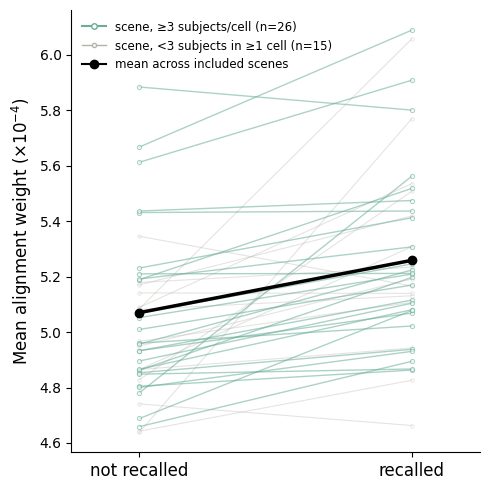

In [15]:
plot_scale = 1e4
ws_plot = within_scene.copy()
ws_plot[[False, True, 'diff']] *= plot_scale

fig, ax = plt.subplots(figsize=(5, 5))

for _, row in ws_plot.loc[~ws_plot['included']].iterrows():
    ax.plot([0, 1], [row[False], row[True]], color='#B4B2A9', alpha=0.35, lw=0.8,
            marker='o', ms=2.5, markerfacecolor='white', markeredgewidth=0.6, zorder=1)

for _, row in ws_plot.loc[ws_plot['included']].iterrows():
    ax.plot([0, 1], [row[False], row[True]], color='#69AD99', alpha=0.55, lw=1,
            marker='o', ms=3, markerfacecolor='white', markeredgewidth=0.8, zorder=2)

inc_plot = ws_plot.loc[ws_plot['included']]
ax.plot([0, 1], [inc_plot[False].mean(), inc_plot[True].mean()],
        color='black', lw=2.5, marker='o', ms=6, zorder=4)

proxies = [
    Line2D([0], [0], color='#69AD99', lw=1.5, marker='o', ms=4, markerfacecolor='white',
           label=f'scene, ≥3 subjects/cell (n={len(inc_plot)})'),
    Line2D([0], [0], color='#B4B2A9', lw=1, marker='o', ms=3, markerfacecolor='white',
           label=f'scene, <3 subjects in ≥1 cell (n={len(ws_plot) - len(inc_plot)})'),
    Line2D([0], [0], color='black', lw=1.5, marker='o', ms=6, label='mean across included scenes'),
]

ax.legend(handles=proxies, frameon=False, fontsize=8.5, loc='upper left')
ax.set_xlim(-0.25, 1.25)
ax.set_xticks([0, 1])
ax.set_xticklabels(['not recalled', 'recalled'], fontsize=12)
ax.set_ylabel(r'Mean alignment weight ($\times 10^{-4}$)', fontsize=12)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()

In [19]:
instance_rows = []

for (sub, recall_instance, recalled_scene), g in alignment_df.groupby(['sub', 'recall_instance', 'recalled_scene']):
    movie_vec = g.set_index('encoding_scene')['mass_per_tr'].reindex(enc_order).fillna(0).to_numpy()

    if movie_vec.sum() == 0:
        continue

    movie_vec /= movie_vec.sum()
    true_idx = enc_index[int(recalled_scene)]
    order = np.argsort(movie_vec)[::-1]
    rank = np.where(order == true_idx)[0][0]

    instance_rows.append({
        'sub': sub,
        'recall_instance': recall_instance,
        'recalled_scene': int(recalled_scene),
        'true_idx': true_idx,
        'rank': rank,
        'movie_vec': movie_vec,
    })

rank_acc = 1 - np.mean([r['rank'] for r in instance_rows]) / (n_scene - 1)
top1 = np.mean([r['rank'] == 0 for r in instance_rows])

print(f'n recall instances = {len(instance_rows)}')
print(f'top-1 accuracy = {top1:.1%}')
print(f'normalized rank accuracy = {rank_acc:.3f}')

n recall instances = 573
top-1 accuracy = 15.7%
normalized rank accuracy = 0.737


In [16]:
conf = np.zeros((n_scene, n_scene))

for row in instance_rows:
    conf[row['true_idx']] += row['movie_vec']

valid_rows = conf.sum(axis=1) > 0
conf_plot = conf[valid_rows]
conf_disp = conf_plot / conf_plot.sum(axis=1, keepdims=True)

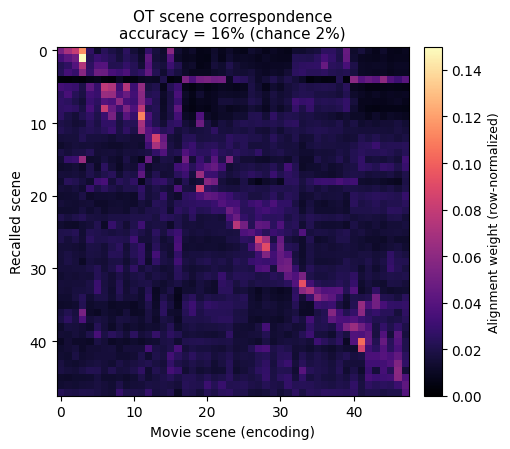

In [17]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))

im = ax.imshow(conf_disp, cmap='magma', aspect='auto', vmin=0)

ax.set_xlabel('Movie scene (encoding)')
ax.set_ylabel('Recalled scene')
ax.set_title(f'OT scene correspondence\naccuracy = {top1:.0%} (chance {1 / n_scene:.0%})', fontsize=11)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Alignment weight (row-normalized)', fontsize=9)

fig.tight_layout()